# Machine Learning-Based Cardiometabolic Risk Stratification Using Population Health Data: An Explainable Clinical Decision Support System

## Notebook 5: Evidence-Based Clinical Knowledge Graph and Agentic Reasoning

**Student Name:** Vanshika Karnwal | Student ID: 201957572  
**Supervisor:** Dr Baoru Huang  
**Module:** COMP702 Dissertation | University of Liverpool  
**Dataset:** NHANES 2017-March 2020 Pre-Pandemic  
**Source:** https://wwwn.cdc.gov/nchs/nhanes/Default.aspx

### Overview
This notebook constructs an evidence-based clinical knowledge graph by 
extracting recommendations from official NICE guideline PDFs using 
natural language processing. A rule-based agentic reasoning layer then 
queries this graph to generate personalised clinical action plans.

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pdfplumber
import os
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded")

Libraries loaded


In [2]:
GUIDELINES_PATH = r'C:\Users\VANSHIKA KARNWAL\OneDrive\Desktop\DISSERTATION\GUIDELINES'

pdfs = [f for f in os.listdir(GUIDELINES_PATH) if f.endswith('.pdf')]
print("Guidelines available:")
for pdf in pdfs:
    print(f"  • {pdf}")

Guidelines available:
  • chronic-kidney-disease-assessment-and-management-NICE.pdf
  • hypertension-in-adults-diagnosis-and-management-NICE.pdf
  • overweight-and-obesity-management-NICE.pdf
  • type-2-diabetes-in-adults-management-pdf-NICE.pdf


## 1. Guideline Recommendation Extraction

Clinical recommendations are extracted from official NICE guideline PDFs
using keyword-based natural language processing. Sentences containing
clinical action keywords (offer, consider, refer, monitor, advise, etc.)
and clinical condition terms are retained as candidate recommendations.
Boilerplate administrative text is filtered out.

**Guidelines used:**
- NICE NG203 (2021) - Chronic Kidney Disease
- NICE NG133 (2019) - Hypertension in Adults  
- NICE NG136 (2022) - Obesity Management
- NICE T2DM - Type 2 Diabetes Management

In [3]:
def extract_clinical_recommendations(pdf_path, guideline_name):
    """
    Extract clinical recommendations from NICE guideline PDFs
    using keyword-based NLP filtering
    """
    recommendations = []
    
    clinical_keywords = ['offer', 'consider', 'refer', 'monitor',
                        'advise', 'measure', 'treat', 'prescribe',
                        'provide', 'screen', 'recommend', 'assess']
    
    skip_keywords = ['copyright', 'nice 2', 'responsibility',
                    'yellow card', 'adverse events', 'www.nice',
                    'all rights', 'when exercising', 'this guideline',
                    'overview', 'when a recommendation', 'guideline covers']
    
    with pdfplumber.open(pdf_path) as pdf:
        for page in pdf.pages:
            text = page.extract_text()
            if not text:
                continue
            sentences = text.replace('\n', ' ').split('.')
            for sentence in sentences:
                sentence = sentence.strip()
                if len(sentence) < 50 or len(sentence) > 300:
                    continue
                if any(skip in sentence.lower() for skip in skip_keywords):
                    continue
                if any(keyword in sentence.lower() for keyword in clinical_keywords):
                    if any(term in sentence.lower() for term in [
                        'egfr', 'kidney', 'blood pressure', 'glucose',
                        'diabetes', 'obesity', 'bmi', 'cholesterol',
                        'patient', 'people with', 'adults with',
                        'risk', 'creatinine', 'hypertension',
                        'cardiovascular', 'weight'
                    ]):
                        recommendations.append({
                            'guideline': guideline_name,
                            'recommendation': sentence
                        })
    return recommendations

print("Extraction function defined")

Extraction function defined


In [4]:
guideline_files = {
    'NICE_NG203': 'chronic-kidney-disease-assessment-and-management-NICE.pdf',
    'NICE_NG133': 'hypertension-in-adults-diagnosis-and-management-NICE.pdf',
    'NICE_NG136': 'overweight-and-obesity-management-NICE.pdf',
    'NICE_T2DM':  'type-2-diabetes-in-adults-management-pdf-NICE.pdf'
}

all_recommendations = []

for guideline_name, filename in guideline_files.items():
    path = os.path.join(GUIDELINES_PATH, filename)
    recs = extract_clinical_recommendations(path, guideline_name)
    all_recommendations.extend(recs)
    print(f"{guideline_name}: {len(recs)} recommendations extracted")

recs_df = pd.DataFrame(all_recommendations)
print(f"\nTotal recommendations extracted: {len(recs_df)}")
print(recs_df.head(3))

NICE_NG203: 195 recommendations extracted
NICE_NG133: 197 recommendations extracted
NICE_NG136: 275 recommendations extracted
NICE_T2DM: 247 recommendations extracted

Total recommendations extracted: 914
    guideline                                     recommendation
0  NICE_NG203  Chronic kidney disease: assessment and managem...
1  NICE_NG203  5 Risk assessment, referral criteria and share...
2  NICE_NG203  9 Assessing and optimising erythropoiesis in p...


## 2. Evidence-Based Knowledge Graph Construction

A directed knowledge graph is constructed from extracted recommendations.
Nodes represent clinical concepts (conditions, guidelines, interventions).
Edges represent relationships derived from real guideline text.

In [5]:
KG = nx.DiGraph()

# Define concept mappings
condition_map = {
    'CKD': ['kidney', 'egfr', 'creatinine', 'renal', 'ckd'],
    'Hypertension': ['blood pressure', 'hypertension', 'systolic', 'diastolic'],
    'Obesity': ['obesity', 'overweight', 'bmi', 'weight'],
    'Diabetes': ['diabetes', 'glucose', 'hba1c', 'glycaemic'],
    'CVD_Risk': ['cardiovascular', 'heart', 'stroke', 'cvd']
}

intervention_map = {
    'Lifestyle_Modification': ['lifestyle', 'diet', 'physical activity', 'behaviour'],
    'BP_Medication': ['antihypertensive', 'ace inhibitor', 'blood pressure medication'],
    'Weight_Management': ['weight management', 'weight loss', 'bariatric', 'calorie'],
    'Diabetes_Screening': ['screening', 'hba1c test', 'glucose test'],
    'Renal_Monitoring': ['monitor kidney', 'egfr monitoring', 'renal function'],
    'Statin_Therapy': ['statin', 'cholesterol lowering', 'lipid lowering'],
    'Smoking_Cessation': ['smoking cessation', 'stop smoking', 'quit smoking'],
    'Exercise_Prescription': ['physical activity', 'exercise', 'aerobic']
}

# Add nodes
for condition in condition_map:
    KG.add_node(condition, node_type='condition')
for intervention in intervention_map:
    KG.add_node(intervention, node_type='intervention')
for guideline in guideline_files.keys():
    KG.add_node(guideline, node_type='guideline')

# Build edges from real recommendation text
for _, row in recs_df.iterrows():
    rec_lower = row['recommendation'].lower()
    guideline = row['guideline']

    mentioned_conditions = [c for c, kws in condition_map.items()
                           if any(kw in rec_lower for kw in kws)]
    mentioned_interventions = [i for i, kws in intervention_map.items()
                               if any(kw in rec_lower for kw in kws)]

    for condition in mentioned_conditions:
        if not KG.has_edge(condition, guideline):
            KG.add_edge(condition, guideline, source='extracted')

    for intervention in mentioned_interventions:
        if not KG.has_edge(guideline, intervention):
            KG.add_edge(guideline, intervention, source='extracted')

print(f"Knowledge Graph built from real NICE guidelines")
print(f"Nodes: {KG.number_of_nodes()}")
print(f"Edges: {KG.number_of_edges()}")
print(f"\nNode types:")
for node_type in ['condition', 'guideline', 'intervention']:
    count = sum(1 for n in KG.nodes() if KG.nodes[n].get('node_type') == node_type)
    print(f"  {node_type}: {count}")

Knowledge Graph built from real NICE guidelines
Nodes: 17
Edges: 34

Node types:
  condition: 5
  guideline: 4
  intervention: 8


## 3. Knowledge Graph Visualisation

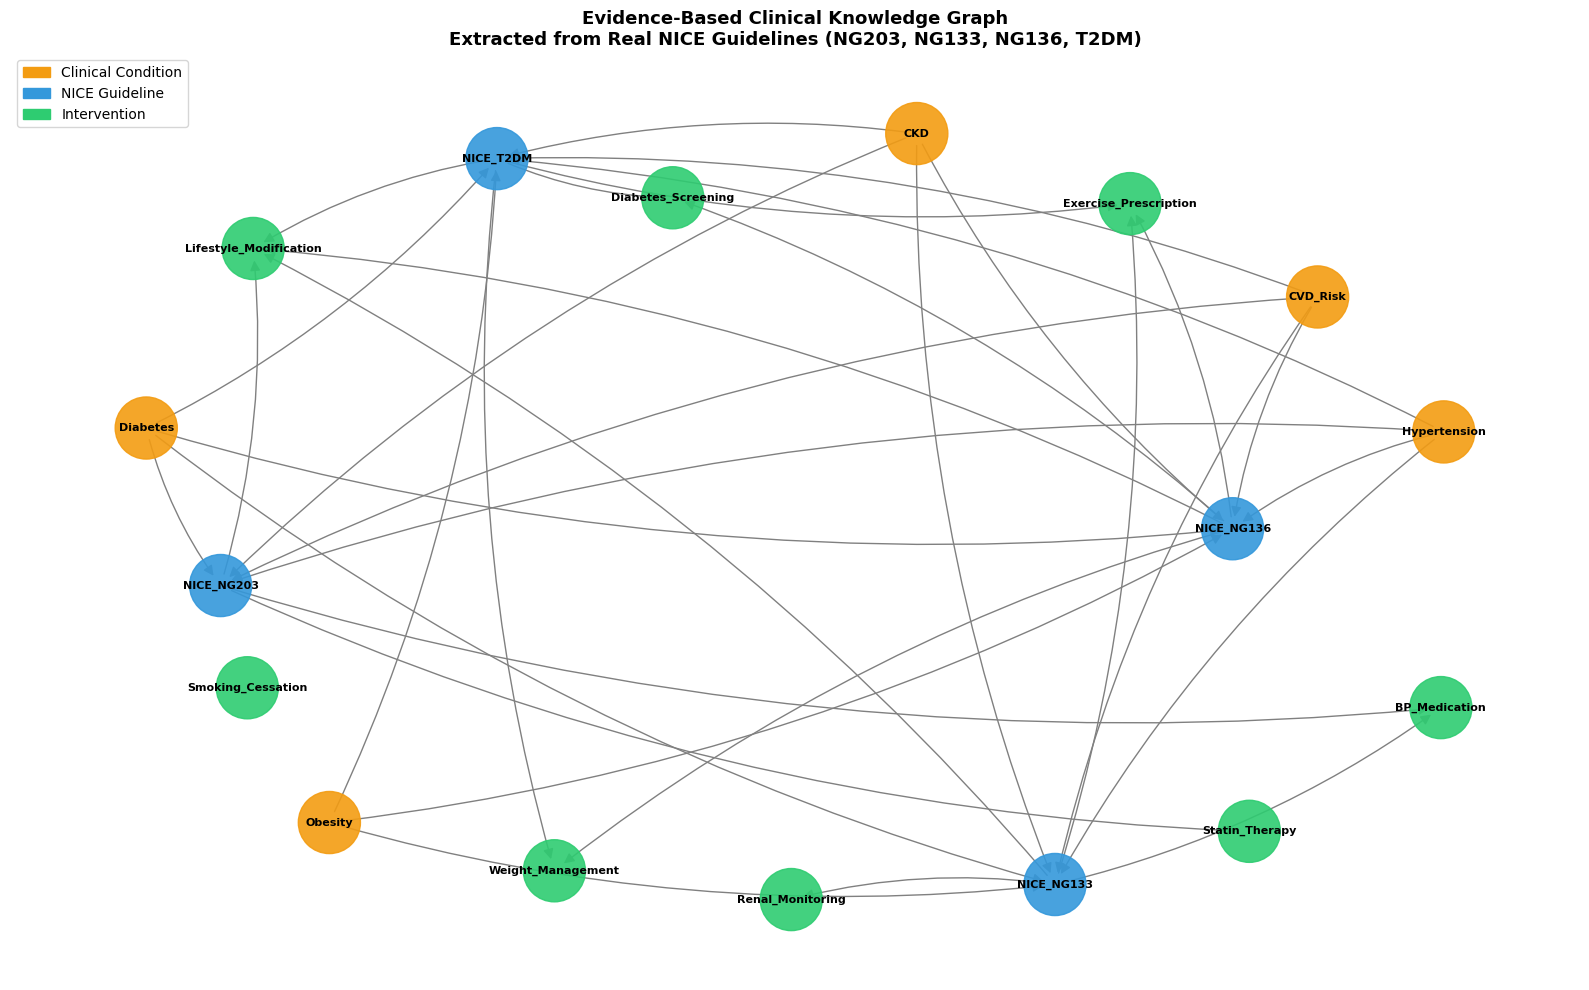

In [6]:
color_map = {
    'condition': '#f39c12',
    'guideline': '#3498db',
    'intervention': '#2ecc71'
}

node_colors = [color_map.get(KG.nodes[n].get('node_type', 'condition'), '#95a5a6')
               for n in KG.nodes()]

plt.figure(figsize=(16, 10))
pos = nx.spring_layout(KG, k=2.5, seed=42)

nx.draw_networkx_nodes(KG, pos, node_color=node_colors,
                        node_size=2000, alpha=0.9)
nx.draw_networkx_labels(KG, pos, font_size=8, font_weight='bold')
nx.draw_networkx_edges(KG, pos, edge_color='grey',
                        arrows=True, arrowsize=15,
                        connectionstyle='arc3,rad=0.1')

legend_elements = [
    mpatches.Patch(color='#f39c12', label='Clinical Condition'),
    mpatches.Patch(color='#3498db', label='NICE Guideline'),
    mpatches.Patch(color='#2ecc71', label='Intervention')
]
plt.legend(handles=legend_elements, loc='upper left', fontsize=10)
plt.title('Evidence-Based Clinical Knowledge Graph\nExtracted from Real NICE Guidelines (NG203, NG133, NG136, T2DM)',
          fontsize=13, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig('knowledge_graph_evidence_based.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Agentic Reasoning Layer

A rule-based agentic reasoning engine queries the knowledge graph
to generate personalised, guideline-informed clinical action plans.
The agent takes ML prediction outputs and patient-specific values
as inputs and returns structured clinical recommendations with
official guideline citations.

In [7]:
def agentic_clinical_reasoning(risk_category, egfr, smoking_status, pa_minutes):
    """
    Rule-based agentic reasoning engine
    Queries clinical knowledge graph and generates personalised action plans
    
    References:
    - NICE NG203 (2021): Chronic Kidney Disease
    - NICE NG133 (2019): Hypertension in Adults
    - NICE NG136 (2022): Obesity Management
    - NICE NG28 (2019): Type 2 Diabetes Prevention
    - ADA Standards of Care 2024
    - ACC/AHA 2019 Cardiovascular Risk Guidelines
    - WHO Physical Activity Guidelines 2020
    - KDIGO 2021: CKD Evaluation and Management
    """
    actions = []
    urgent_flags = []
    guidelines_cited = []

    if risk_category == 'High':
        actions.append("Urgent clinical evaluation recommended")
        urgent_flags.append("HIGH CARDIOMETABOLIC RISK - Immediate clinical review advised")
        if egfr < 60:
            actions.append("Refer to nephrology - eGFR <60 indicates CKD Stage 3+")
            guidelines_cited.append("NICE NG203 (2021): Refer if eGFR <60 mL/min/1.73m²")
            guidelines_cited.append("KDIGO 2021: eGFR <60 warrants specialist evaluation")
            urgent_flags.append("CKD DETECTED - Nephrology referral required")
        elif egfr < 90:
            actions.append("Monitor kidney function annually (eGFR mildly reduced)")
            guidelines_cited.append("NICE NG203 (2021): Annual eGFR monitoring if mildly reduced")
        if smoking_status == 'Current':
            actions.append("Refer to NHS Stop Smoking Service immediately")
            guidelines_cited.append("NICE PH10 (2008): Brief smoking cessation interventions")
            urgent_flags.append("CURRENT SMOKER - Cessation support priority")
        if pa_minutes < 150:
            actions.append("Physical activity programme - target ≥150 min/week moderate activity")
            guidelines_cited.append("WHO Physical Activity Guidelines 2020: 150-300 min/week")
        actions.append("Consider statin therapy assessment")
        actions.append("Blood pressure monitoring - treat if ≥140/90 mmHg")
        actions.append("HbA1c and fasting glucose testing for diabetes screening")
        guidelines_cited.append("ACC/AHA 2019: Statin therapy for high CVD risk")
        guidelines_cited.append("NICE NG133 (2019): Treat hypertension if ≥140/90 mmHg")
        guidelines_cited.append("ADA Standards 2024: Annual diabetes screening")

    elif risk_category == 'Moderate':
        actions.append("Lifestyle modification programme recommended")
        guidelines_cited.append("NICE NG28 (2019): Prevent T2DM through lifestyle intervention")
        if egfr < 60:
            actions.append("Monitor kidney function - eGFR below 60")
            guidelines_cited.append("NICE NG203 (2021): CKD monitoring required")
        if smoking_status == 'Current':
            actions.append("Refer to NHS Stop Smoking Service")
            guidelines_cited.append("NICE PH10: Smoking cessation support")
        if pa_minutes < 150:
            actions.append("Increase physical activity to ≥150 minutes/week")
            guidelines_cited.append("WHO 2020: 150-300 min/week moderate intensity activity")
        actions.append("Repeat cardiometabolic screening in 6-12 months")
        actions.append("Weight management support if BMI ≥30 kg/m²")
        guidelines_cited.append("NICE NG136 (2022): Weight management for adults with obesity")

    else:
        actions.append("Maintain current healthy lifestyle")
        actions.append("Routine cardiometabolic screening every 3-5 years")
        guidelines_cited.append("NICE NG28: Routine screening for low-risk adults")
        if smoking_status == 'Current':
            actions.append("Smoking cessation strongly advised")
            guidelines_cited.append("NICE PH10: Cessation support for all smokers")
        if pa_minutes < 150:
            actions.append("Increase physical activity to meet WHO guidelines")
            guidelines_cited.append("WHO 2020: Minimum 150 min/week physical activity")

    return {
        'risk_category': risk_category,
        'urgent_flags': urgent_flags,
        'recommended_actions': actions,
        'guidelines_cited': list(set(guidelines_cited))
    }

print("Agentic reasoning engine defined")

Agentic reasoning engine defined


In [8]:
# Test case - High risk patient with CKD and smoking
test_result = agentic_clinical_reasoning(
    risk_category='High',
    egfr=45,
    smoking_status='Current',
    pa_minutes=60
)

print("=" * 60)
print("AGENTIC REASONING OUTPUT - TEST PATIENT")
print("=" * 60)
print(f"\nRisk Category: {test_result['risk_category']}")

print(f"\nURGENT FLAGS:")
for flag in test_result['urgent_flags']:
    print(f"  ⚠ {flag}")

print(f"\nRECOMMENDED ACTIONS:")
for action in test_result['recommended_actions']:
    print(f"  • {action}")

print(f"\nGUIDELINES CITED:")
for guideline in test_result['guidelines_cited']:
    print(f"  📖 {guideline}")

AGENTIC REASONING OUTPUT - TEST PATIENT

Risk Category: High

URGENT FLAGS:
  ⚠ HIGH CARDIOMETABOLIC RISK - Immediate clinical review advised
  ⚠ CKD DETECTED - Nephrology referral required
  ⚠ CURRENT SMOKER - Cessation support priority

RECOMMENDED ACTIONS:
  • Urgent clinical evaluation recommended
  • Refer to nephrology - eGFR <60 indicates CKD Stage 3+
  • Refer to NHS Stop Smoking Service immediately
  • Physical activity programme - target ≥150 min/week moderate activity
  • Consider statin therapy assessment
  • Blood pressure monitoring - treat if ≥140/90 mmHg
  • HbA1c and fasting glucose testing for diabetes screening

GUIDELINES CITED:
  📖 NICE NG203 (2021): Refer if eGFR <60 mL/min/1.73m²
  📖 NICE PH10 (2008): Brief smoking cessation interventions
  📖 WHO Physical Activity Guidelines 2020: 150-300 min/week
  📖 NICE NG133 (2019): Treat hypertension if ≥140/90 mmHg
  📖 KDIGO 2021: eGFR <60 warrants specialist evaluation
  📖 ADA Standards 2024: Annual diabetes screening
  📖 

In [9]:
SAVE_PATH = r'C:\Users\VANSHIKA KARNWAL\OneDrive\Desktop\DISSERTATION'
nx.write_gml(KG, f'{SAVE_PATH}\\clinical_kg_evidence_based.gml')
print("Evidence-based knowledge graph saved")
print(f"Nodes: {KG.number_of_nodes()}")
print(f"Edges: {KG.number_of_edges()}")

Evidence-based knowledge graph saved
Nodes: 17
Edges: 34
